## Running this notebook

Install the project with the notebook extra before opening this file. Imports
use the installed package and do not change the working directory. Set
`OVERSCREENING_OUTPUT_DIR` to choose a directory for saved files.

The original scientific parameter values and sweep sizes are retained. Several
cells are deliberately expensive or demonstrate a failed solve; they are not
part of the bounded CI examples. Inspect convergence flags before interpreting
results. The optional fsolve initializer and native adjoint fallback have separate
controls; reference continuation remains a third, independent control. After a failed
physical Newton solve it computes a screened linear reference, then follows
the full residual from `q=1` to the physical endpoint `q=0`, retaining accepted
states and reducing the parameter step after failed stages. Source callbacks
remain physical and independent of `q`.
For bounded NumPy/mpmath demonstrations, run the scripts in `examples/`.

Ordinary BSK examples construct a fresh immutable `BSKProblem`; there are no
parameter setters in that interface. The initial problem defaults retain
sigma=10, mu=0, gamma=0.5, delta=50 and wall value 100. Every later parameter
block specifies its physical values and boundary data explicitly. Finite
segments use `domain` and both endpoint boundary rows. Unsupported boundary experiments have a separate opt-in research notebook.

Live solver diagnostics use `verbosity=2` in this notebook. Set it to `0`
for quiet solves, `1` for phase summaries, or `3` for trial details.


## This notebook provides a set of examples on how to use the numerical method for the overscreening breakdown problem.

#### The equations under consideration in a general form are:
$$
u_{xx} - \delta^2 u_{xxxx} = f(u, x), x\in[0, \infty)
$$

#### where the right hand side function for the overscreening breakdown problem is formulated as:

$$
f(u,x) :=  \frac{\sinh(u)}{1 +2\gamma \sinh^2\left(u/2\right)} - \frac{0.5 \Phi(x) e^{u}}{1 +2\gamma \sinh^2\left(u/2\right)},
$$


$$
\Phi(x) = \mu \frac{1}{\sqrt{2 \pi}} \exp{\left(-\frac{x^2}{2(\sigma/L_D)^2}\right)}
$$

In [1]:
# Install the project first: python -m pip install -e ".[notebook]"
from pathlib import Path
import os
from matplotlib import pyplot as plt
import numpy as np
import mpmath as mp
from overscreening_breakdown import (
    BSKProblem, MpmathArithmetic, solve, load_solution,
    ContinuationOptions, ScreenedLinearReference,
)
from overscreening_breakdown.rational_mapping import RationalHalfLineMap
OUTPUT_DIR = Path(os.environ.get("OVERSCREENING_OUTPUT_DIR", "notebook-output")).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

def display_values(function, coordinates):
    # Float conversion is confined to plot data.
    return np.array([float(function(value)) for value in coordinates])

def mapped_values(result, angles):
    a = result.arithmetic
    if result.domain[1] == a.inf:
        mapping = RationalHalfLineMap(a, L=result.L)
        coordinates = [mapping.from_angle(a.scalar(value)) for value in angles]
    else:
        left, right = result.domain
        coordinates = [(a.cos(a.scalar(value))*(right-left)+(right+left))/2 for value in angles]
    return display_values(result.u, coordinates)

def run_collocation(problem, N, *, L=1, tolerance="1e-10", method="newton",
                    max_iterations=50, globalization=True, continuation=None, initial=None,
                    use_mpmath=False, precision=100, initializer=None,
                    initializer_tolerance="0.1", initializer_max_evaluations=200,
                    newton_fallback=None, adjoint_max_steps=20, verbosity=2,
                    progress_callback=None, progress_interval=1.0):
    if initial is not None and hasattr(initial, "coefficients"):
        initial = (initial.coefficients if initial.N == N
                   else lambda x, a, previous=initial: previous.u(x))
    return solve(problem, N, solver="collocation", L=L, tolerance=tolerance,
                 method=method, max_iterations=max_iterations,
                 use_globalization=globalization, continuation=continuation,
                 initial_guess=initial,
                 use_mpmath=use_mpmath, precision=precision,
                 initializer=initializer, initializer_tolerance=initializer_tolerance,
                 initializer_max_evaluations=initializer_max_evaluations,
                 newton_fallback=newton_fallback, adjoint_max_steps=adjoint_max_steps,
                 verbosity=verbosity, progress_callback=progress_callback,
                 progress_interval=progress_interval)


In [2]:
#init the problem

problem = BSKProblem()

In [3]:
# Numerical parameters are unchanged from the original notebook.
N = 100
domain = [0,np.inf]
tolerance = 1.0e-10
use_method = "newton"
initializer = None
L = 6


### On how to select the parameter $L$, see [bellow](#check_L_values).
But we recommend exploring all cells to be certain on what you are doing.

In [4]:
#set up the problem.
#If a parameter is not given, then a default value is used instead. 
#See the source file of "overscreening_breakdown" for more details for defauls values

sigma = 20.0
mu = 0.36
gamma = 1
delta = 10.0
u0 = 1.0
u0xxx = 0

#use some function as initial guess for the root in the Newton's method.
def some_func(x, a):
    return u0 * a.exp(-x)

#apply parameters
problem = BSKProblem(sigma=sigma, mu=mu, gamma=gamma, delta=delta, boundary_conditions=((u0, None, None, u0xxx, None), (None,)*5), initial_guess=some_func)

In [5]:
# The physical description is passed directly to solve; no solver mutation is needed.
print(problem.domain, problem.boundary_conditions)


(0, 'inf') ((1.0, None, None, 0, None), (None, None, None, None, None))


In [6]:
result = run_collocation(problem, N, L=L, tolerance=tolerance, method=use_method)
c = result.coefficients


[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=yes initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000878199 elapsed=0.002s
[collocation/newton] problem_ready unknown_count=102 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=102 elapsed=0.382s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=102 success=yes duration=2.473869 elapsed=2.855s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.856s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1678244 elapsed=3.024s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=3.025s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual

In [7]:
# fsolve is an optional NumPy initializer; Newton still verifies the final residual.
initializer = "fsolve"
result_ao = run_collocation(problem, N, L=L, tolerance=tolerance,
                            method=use_method, initializer=initializer)
c_ao = result_ao.coefficients


[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=yes initializer=fsolve newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.001621881 elapsed=0.003s
[collocation/newton] problem_ready unknown_count=102 norm=rms elapsed=0.004s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=102 elapsed=0.049s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=102 success=yes duration=2.42909 elapsed=2.478s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.479s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1686817 elapsed=2.648s
[collocation/newton] initializer_start norm=rms initializer=fsolve budget=200 step_tolerance=1.e-01 homotopy=0e+00 elapsed=2.648s
[collocation/newton] i

In [8]:
#check solution relative difference
np.linalg.norm(c_ao - c)/np.linalg.norm(c)

np.float64(6.236437256118569e-09)

In [9]:
# Typed JSON records solver type, basis, mapping, precision and physical metadata.
path = OUTPUT_DIR / "solution.json"
result.save(path)
restored = load_solution(path, problem=problem, solver="collocation")
print("saved coefficient difference:", result.arithmetic.norm(result.coefficients-restored.coefficients))
# Same-solver restart; use project_collocation explicitly before a Galerkin restart.
restarted = solve(problem, N, solver="collocation", L=L, tolerance=tolerance,
                  initial_guess=restored, verbosity=2)


saved coefficient difference: 0.0
[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=yes initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000518301 elapsed=0.001s
[collocation/newton] problem_ready unknown_count=102 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=102 elapsed=0.017s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=102 success=yes duration=2.504913 elapsed=2.522s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.523s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1862964 elapsed=2.709s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=2.710s
[collocation/newton] stage_residual norm=r

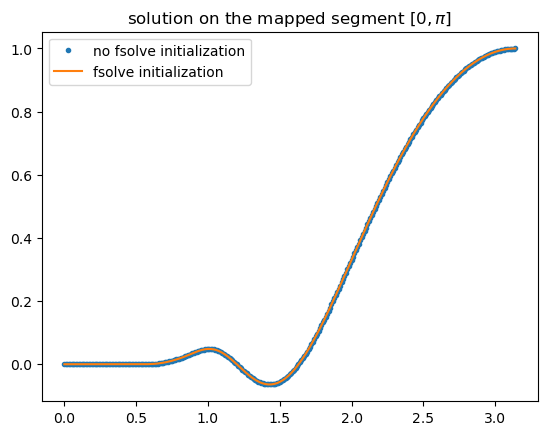

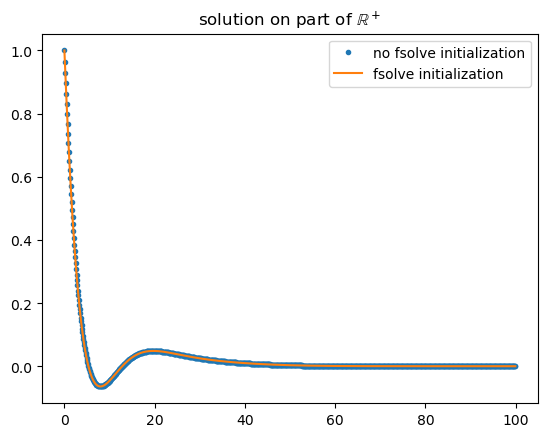

In [10]:
t = np.arange(0, np.pi, 0.01)
plt.title(r"solution on the mapped segment $[0,\pi]$")
plt.plot(t, mapped_values(result, t), '.')
plt.plot(t, mapped_values(result_ao, t))
plt.legend(["no fsolve initialization", "fsolve initialization"])
plt.show()
x = np.arange(0.0, 100.0, 0.1)
plt.title(r"solution on part of $\mathbb{R}^+$")
plt.plot(x, display_values(result.u, x), '.')
plt.plot(x, display_values(result_ao.u, x))
plt.legend(["no fsolve initialization", "fsolve initialization"])
plt.show()


Next we demonstrate resolution continuation for a deliberately stiff problem.
The scientific parameters and the difficult unit-amplitude Gaussian are retained.
This experiment transfers accepted fields as the spectral resolution changes.
The far-field value is prescribed explicitly as zero for both the physical
problem and its reference.


In [11]:
#we are setting initial parameters to the problem for this test, specially desiged to be very stiff
sigma = 10.0
mu = 1
gamma = 1/2
delta = 50.0
u0 = 100.0
u0xxx = 0

# Deliberately use unit amplitude even though the wall value is 100.
# Keep this difficult guess unchanged when comparing recovery strategies.
def some_func(x, a):
    return a.exp(-x ** 2) 

problem = BSKProblem(sigma=sigma, mu=mu, gamma=gamma, delta=delta, boundary_conditions=((u0, None, None, u0xxx, None), (0, None, None, None, None)), initial_guess=some_func)

In [12]:
# This deliberately stiff solve may fail; inspect the status rather than assuming success.
N = 100
result = run_collocation(problem, N, L=L, tolerance=tolerance, method=use_method,
                         max_iterations=20, globalization=False,
                         initializer=None, use_mpmath=False)
c = result.coefficients


[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.002s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.001077739 elapsed=0.003s
[collocation/newton] problem_ready unknown_count=103 norm=rms elapsed=0.004s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=0.051s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.547419 elapsed=2.598s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.599s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1840727 elapsed=2.783s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=2.784s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_

/data/Programs/overscreening_breakdown/src/overscreening_breakdown/arithmetic.py:46: RuntimeWarning: overflow encountered in sinh
  return self.context.sinh(value)
/data/Programs/overscreening_breakdown/src/overscreening_breakdown/problems/bsk.py:21: RuntimeWarning: overflow encountered in scalar power
  denominator = 1 + 2*gamma*arithmetic.sinh(half*u)**2
/data/Programs/overscreening_breakdown/src/overscreening_breakdown/problems/bsk.py:22: RuntimeWarning: invalid value encountered in scalar divide
  return numerator/denominator
/data/Programs/overscreening_breakdown/src/overscreening_breakdown/arithmetic.py:43: RuntimeWarning: overflow encountered in exp
  return self.context.exp(value)
/data/Programs/overscreening_breakdown/src/overscreening_breakdown/problems/bsk.py:20: RuntimeWarning: invalid value encountered in scalar subtract
  numerator = arithmetic.sinh(u) - half*mu*_gaussian(x, sigma, arithmetic)*arithmetic.exp(u)
/data/Programs/overscreening_breakdown/src/overscreening_brea

[collocation/newton] iteration_end norm=rms stage=1 iteration=2 homotopy=0e+00 residual_norm=7.41014e+12 target_norm=1.014889e-09 weight=3.051758e-05 backtracks=15 step_kind=newton elapsed=3.596s
[collocation/newton] iteration_start norm=rms stage=1 iteration=3 homotopy=0e+00 residual_norm=7.41014e+12 target_norm=1.014889e-09 step_kind=newton elapsed=3.597s
[collocation/newton] iteration_end norm=rms stage=1 iteration=3 homotopy=0e+00 residual_norm=7.402904e+12 target_norm=1.014889e-09 weight=9.765625e-04 backtracks=10 step_kind=newton elapsed=3.948s
[collocation/newton] iteration_start norm=rms stage=1 iteration=4 homotopy=0e+00 residual_norm=7.402904e+12 target_norm=1.014889e-09 step_kind=newton elapsed=3.949s
[collocation/newton] iteration_end norm=rms stage=1 iteration=4 homotopy=0e+00 residual_norm=7.402452e+12 target_norm=1.014889e-09 weight=6.103516e-05 backtracks=14 step_kind=newton elapsed=4.347s
[collocation/newton] iteration_start norm=rms stage=1 iteration=5 homotopy=0e+00 

/data/Programs/overscreening_breakdown/src/overscreening_breakdown/problems/bsk.py:20: RuntimeWarning: invalid value encountered in scalar multiply
  numerator = arithmetic.sinh(u) - half*mu*_gaussian(x, sigma, arithmetic)*arithmetic.exp(u)


[collocation/newton] iteration_end norm=rms stage=1 iteration=8 homotopy=0e+00 residual_norm=7.369971e+12 target_norm=1.014889e-09 weight=4.882812e-04 backtracks=11 step_kind=newton elapsed=5.762s
[collocation/newton] iteration_start norm=rms stage=1 iteration=9 homotopy=0e+00 residual_norm=7.369971e+12 target_norm=1.014889e-09 step_kind=newton elapsed=5.763s


/data/Programs/overscreening_breakdown/src/overscreening_breakdown/problems/bsk.py:32: RuntimeWarning: overflow encountered in scalar multiply
  return numerator/(2*denominator**2)


[collocation/newton] iteration_end norm=rms stage=1 iteration=9 homotopy=0e+00 residual_norm=7.366372e+12 target_norm=1.014889e-09 weight=4.882812e-04 backtracks=11 step_kind=newton elapsed=6.122s
[collocation/newton] iteration_start norm=rms stage=1 iteration=10 homotopy=0e+00 residual_norm=7.366372e+12 target_norm=1.014889e-09 step_kind=newton elapsed=6.123s
[collocation/newton] iteration_end norm=rms stage=1 iteration=10 homotopy=0e+00 residual_norm=7.251273e+12 target_norm=1.014889e-09 weight=1.5625e-02 backtracks=6 step_kind=newton elapsed=6.424s
[collocation/newton] iteration_start norm=rms stage=1 iteration=11 homotopy=0e+00 residual_norm=7.251273e+12 target_norm=1.014889e-09 step_kind=newton elapsed=6.425s
[collocation/newton] iteration_end norm=rms stage=1 iteration=11 homotopy=0e+00 residual_norm=7.25083e+12 target_norm=1.014889e-09 weight=6.103516e-05 backtracks=14 step_kind=newton elapsed=6.819s
[collocation/newton] iteration_start norm=rms stage=1 iteration=12 homotopy=0e+

In [13]:
# Original 120-digit, N=100 experiment; it can be expensive.
# fsolve is NumPy-only; this native mpmath solve explicitly has no initializer.
print("using u0 =", u0)
def some_func_mp(x, a):
    return a.exp(-x ** 2)
problem_mp = BSKProblem()
problem_mp = BSKProblem(sigma=sigma, mu=mu, gamma=gamma, delta=delta, boundary_conditions=((u0, None, None, u0xxx, None), (0, None, None, None, None)), initial_guess=some_func_mp)
N = 100
use_mpmath = True
prec = 120
tolerance_mp = 1.0e-30
result_mp = run_collocation(problem_mp, N, L=L, tolerance=tolerance_mp, method=use_method,
                            max_iterations=20, globalization=False, use_mpmath=use_mpmath,
                            precision=prec, initializer=None)
c_mp = result_mp.coefficients


using u0 = 100.0
[collocation/newton] solve_start N=100 precision=120 backend=gmpy arithmetic=mpmath tolerance=1.0e-30 use_globalization=no initializer=- newton_fallback=- elapsed=0.001s
[collocation/newton] phase_start phase=problem_binding elapsed=0.002s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000932536 elapsed=0.003s
[collocation/newton] problem_ready unknown_count=103 norm=rms elapsed=0.004s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=0.083s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=12.78643 elapsed=12.870s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=12.870s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=2.143665 elapsed=15.014s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0.0 elapsed=15.015s
[collocation/newton] stage_residual norm=rms stage=1 homo

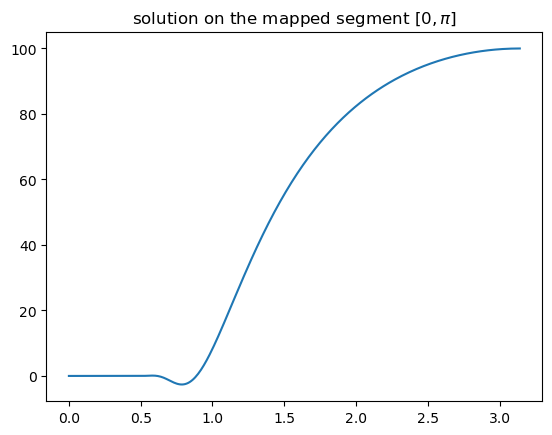

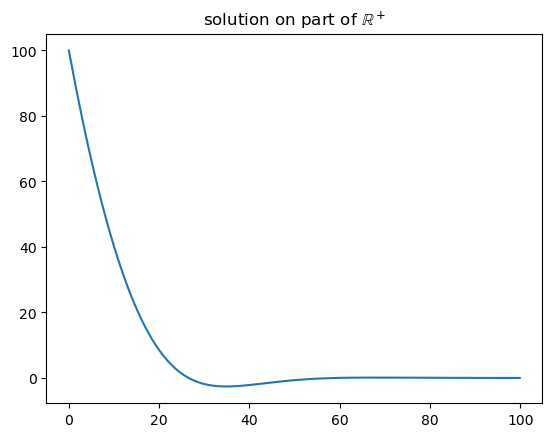

In [16]:
t = np.arange(0, np.pi, 0.01)
x = np.arange(0, 100, 0.1)
plt.title(r"solution on the mapped segment $[0,\pi]$")
plt.plot(t, mapped_values(result_mp, t))
plt.show()
plt.title(r"solution on part of $\mathbb{R}^+$")
plt.plot(x, display_values(result_mp.u, x))
plt.show()

In [17]:
# Original size-globalization sweep; changing N transfers the previous field.
N_base = 10
N = N_base
result1 = None
previous_result = None
it = 2
while it < 12:
    print("running on N =", N)
    result = run_collocation(problem, N, L=L, tolerance=tolerance, method=use_method,
                             max_iterations=20, globalization=False, initial=result1,
                             initializer=None, use_mpmath=False)
    if result.converged:
        previous_result = result1
        result1 = result
        N = N_base*it
        it = it+1
    else:
        N = N-5
c1 = result1.coefficients


running on N = 10
[collocation/newton] solve_start N=10 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.001106583 elapsed=0.002s
[collocation/newton] problem_ready unknown_count=13 norm=rms elapsed=0.003s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=10 unknown_count=13 elapsed=0.026s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=10 unknown_count=13 success=yes duration=0.05234103 elapsed=0.079s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.079s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.003415295 elapsed=0.083s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.083s
[collocation/newton] stage_residual norm=rms stage=1 homotopy

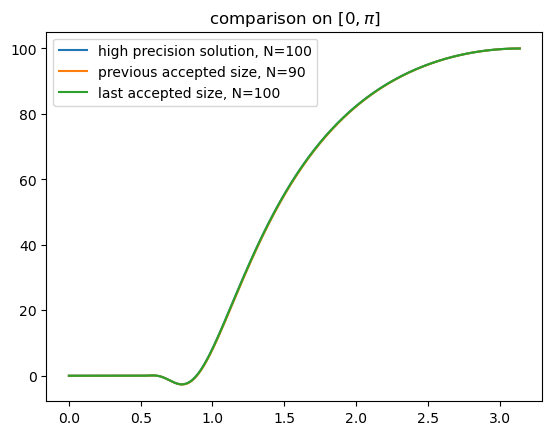

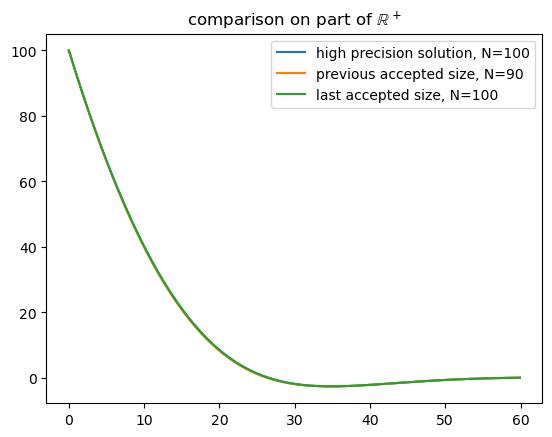

In [23]:
t = np.arange(0, np.pi, 0.01)
x = np.arange(0, 60, 0.1)
comparisons = [("high precision solution", result_mp),
               ("previous accepted size", previous_result), ("last accepted size", result1)]
for label, current in comparisons:
    if current is not None:
        plt.plot(t, mapped_values(current, t), label="{}, N={}".format(label, current.N))
plt.title(r"comparison on $[0,\pi]$")
plt.legend()
plt.show()
for label, current in comparisons:
    if current is not None:
        plt.plot(x, display_values(current.u, x), label="{}, N={}".format(label, current.N))
plt.title(r"comparison on part of $\mathbb{R}^+$")
plt.legend()
plt.show()

Next we demonstrate reference continuation for the same stiff physical problem
and the same deliberately difficult unit Gaussian. No fsolve initialization or
previous size-continuation solution is supplied. NumPy is selected explicitly.

Newton first tries the physical equation. On failure, a native linear solve
computes a screened reference solution with the same boundary data. Accepted
stages then move from `q=1` to the original residual at `q=0`; failed stages
roll back and reduce the parameter step. The physical source callback stays
independent of `q`.

The budget is **20 Newton attempts per stage**, rather than 20 for the entire
path. `ContinuationOptions` also bounds the total Newton attempts (including
the first physical solve) and continuation attempts (including rejected stages).
Reference construction uses a separate initial linear solve and, if needed,
bounded native residual-correction solves without relaxing its target. The final
physical convergence flag must pass before its coefficients are used.


In [24]:
# Same N=100 and deliberately difficult guess; enable reference recovery.
continuation_options = ContinuationOptions(
    reference=ScreenedLinearReference(strength="1"),
    initial_step="0.25", min_step="1e-6", max_step="0.5", growth="1.5",
    max_stages=100, max_total_iterations=1000,
)
globalization_options = dict(
    N=100, L=L, tolerance=tolerance, method="newton",
    max_iterations=20, globalization=True, continuation=continuation_options,
    initializer=None, use_mpmath=False,
)


In [25]:
result2 = run_collocation(problem, **globalization_options)
assert result2.converged, "Reference continuation failed: {}".format(result2.newton_result.reason)
c2 = result2.coefficients
newton_diagnostics = result2.newton_result
print("Newton attempts:", newton_diagnostics.iterations)
print("Continuation attempts:", newton_diagnostics.continuation_attempts)
reference_diagnostics = newton_diagnostics.reference_result
if reference_diagnostics is not None:
    print("Reference verified:", reference_diagnostics.converged,
          "residual:", reference_diagnostics.residual_norm)


[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=yes initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.003s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.001719381 elapsed=0.004s
[collocation/newton] problem_ready unknown_count=103 norm=rms elapsed=0.006s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=0.054s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.453627 elapsed=2.508s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.509s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.172574 elapsed=2.681s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=2.682s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_

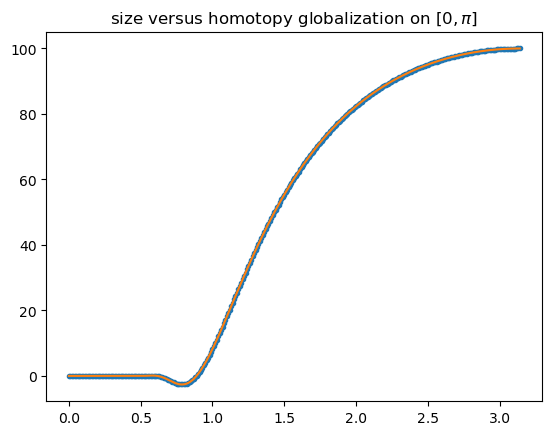

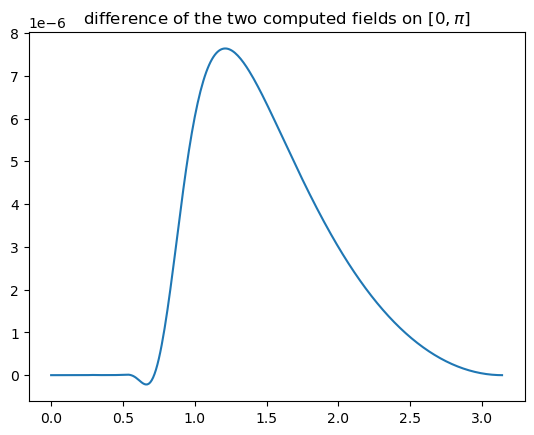

In [26]:
t = np.arange(0, np.pi, 0.01)
sol = mapped_values(result1, t)
sol2 = mapped_values(result2, t)
plt.title(r"size versus homotopy globalization on $[0,\pi]$")
plt.plot(t, sol2, '.')
plt.plot(t, sol)
plt.show()
plt.title(r"difference of the two computed fields on $[0,\pi]$")
plt.plot(t, sol-sol2)
plt.show()


<a id='check_L_values'></a>
## Here we demonstrate how to find a stable value of the mapping parameter L for the given problem.

One should choose the smallest possible value of L at which the solutions are stable w.r.t. the discretization


In [27]:
#setup desired problem parameters for the test

sigma = 10.0
mu = 1
gamma = 1/2
delta = 10.0
u0 = 1.0
u0xxx = 0

#solution initial guess
def some_func(x, a):
    return u0 * a.exp(-x) 

problem = BSKProblem(sigma=sigma, mu=mu, gamma=gamma, delta=delta, boundary_conditions=((u0, None, None, u0xxx, None), (None,)*5), initial_guess=some_func)

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.002s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.001471789 elapsed=0.003s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.004s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.030s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.2430107 elapsed=0.273s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.273s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.01766874 elapsed=0.291s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.291s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm

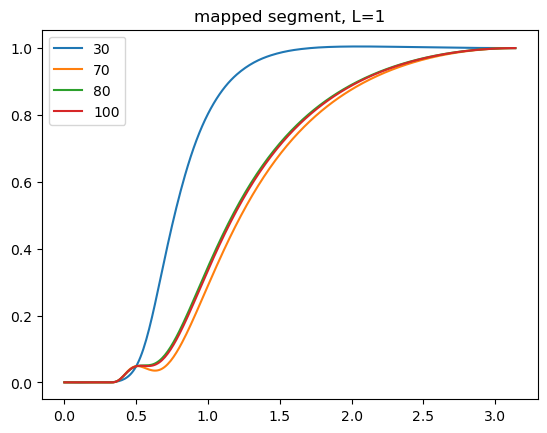

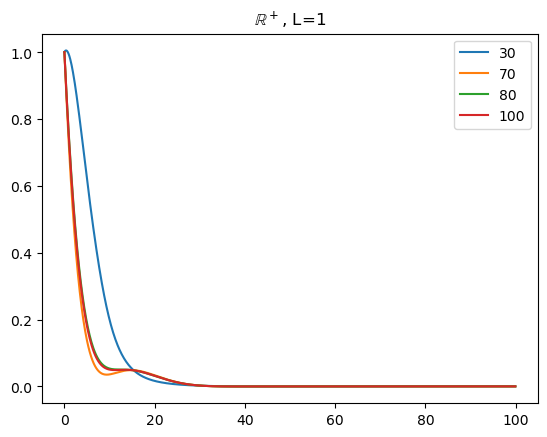

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000792292 elapsed=0.002s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.011s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.2467384 elapsed=0.258s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.259s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.01917028 elapsed=0.278s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.279s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm

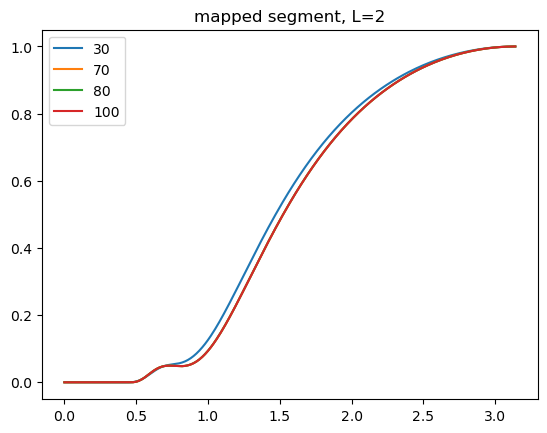

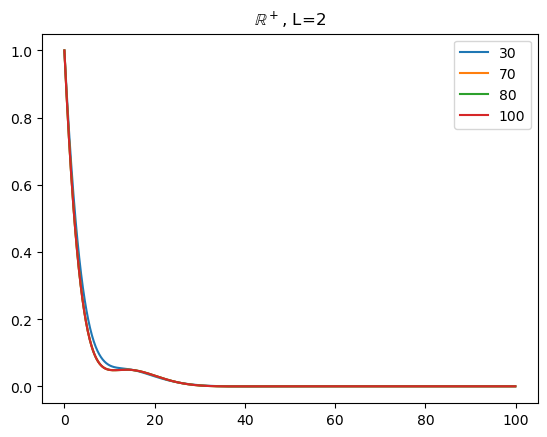

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000819042 elapsed=0.002s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.010s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.25003 elapsed=0.260s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.261s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.01864877 elapsed=0.279s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.280s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=2

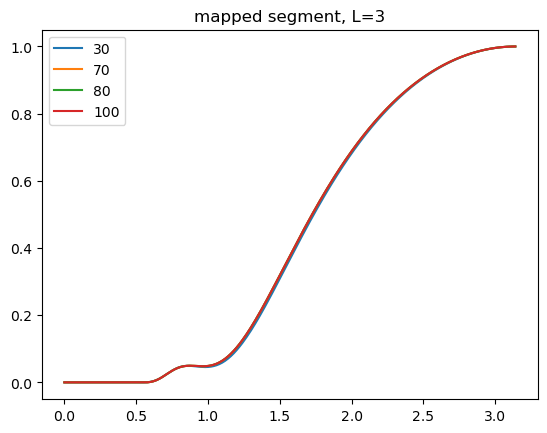

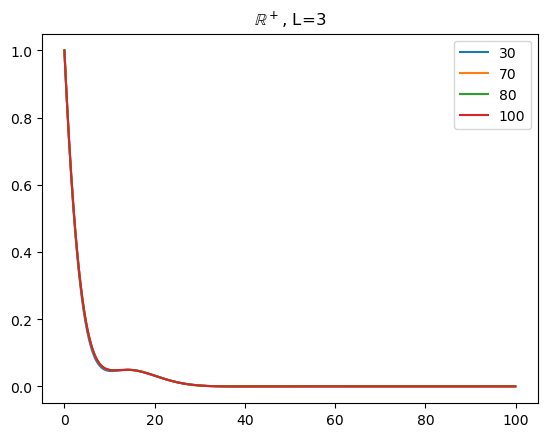

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.000s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000300672 elapsed=0.001s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.001s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.009s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.2380584 elapsed=0.247s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.248s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.0176994 elapsed=0.266s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.267s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=

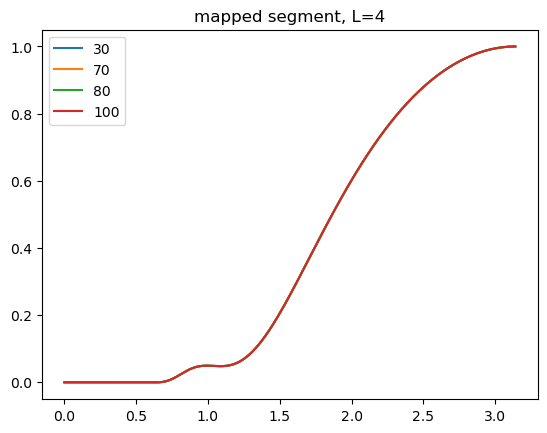

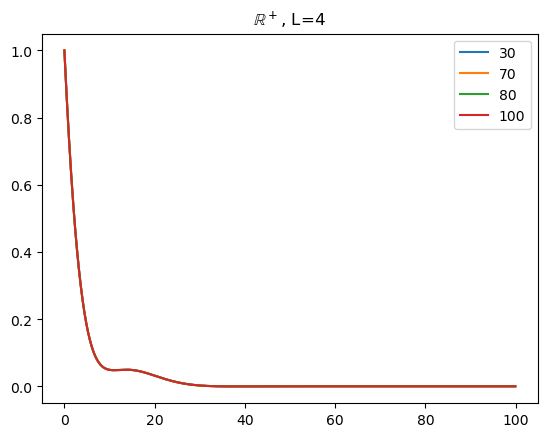

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000587235 elapsed=0.001s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.010s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.2365175 elapsed=0.247s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.248s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.01802088 elapsed=0.266s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.266s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm

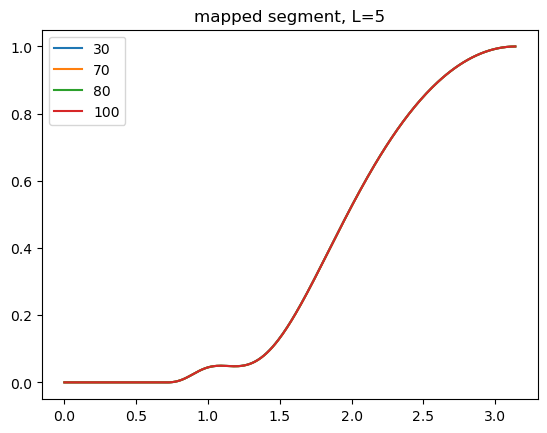

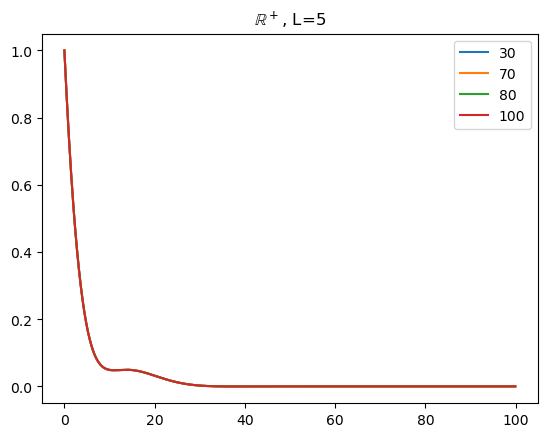

[collocation/newton] solve_start N=30 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000627255 elapsed=0.001s
[collocation/newton] problem_ready unknown_count=32 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=30 unknown_count=32 elapsed=0.010s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=30 unknown_count=32 success=yes duration=0.2390623 elapsed=0.249s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.250s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.01870436 elapsed=0.269s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.269s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm

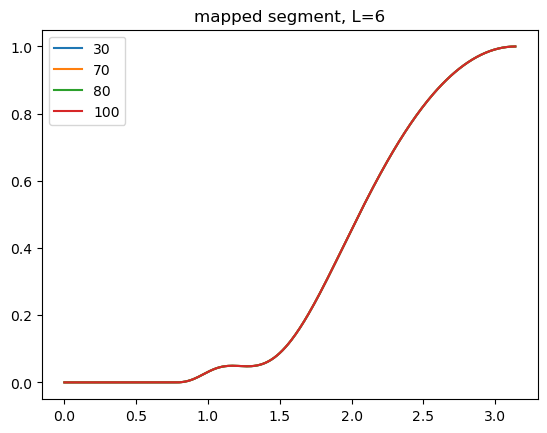

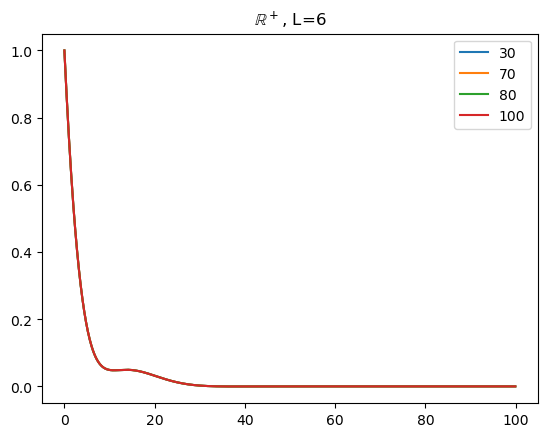

For this problem the original recommendation was L=5 or L=6.


In [28]:
# Original resolution and mapping-length grids are preserved.
Nall = [30,70,80,100]
Lall = [1,2,3,4,5,6]
t = np.arange(0, np.pi, 0.01)
x = np.arange(0, 100, 0.1)
initializer = "fsolve"
for L in Lall:
    results = {}
    previous = None
    for N in Nall:
        current = run_collocation(problem, N, L=L, tolerance=tolerance, method="newton",
                                  max_iterations=20, globalization=False, initial=previous)
        results[N] = current
        previous = current
    for N in Nall:
        plt.plot(t, mapped_values(results[N], t), label=N)
    plt.legend()
    plt.title("mapped segment, L="+str(L))
    plt.show()
    for N in Nall:
        plt.plot(x, display_values(results[N].u, x), label=N)
    plt.legend()
    plt.title(r"$\mathbb{R}^+$, L="+str(L))
    plt.show()
print("For this problem the original recommendation was L=5 or L=6.")


In the section bellow we demonstrate how to solve the Poisson problem in the form:
$$
u_{xx}=f(x,u), x\in[0, \infty)
$$

[collocation/newton] solve_start N=100 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=yes initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000841951 elapsed=0.002s
[collocation/newton] problem_ready unknown_count=101 norm=rms elapsed=0.003s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=101 elapsed=0.028s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=101 success=yes duration=2.545995 elapsed=2.574s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=2.574s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1841751 elapsed=2.759s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=2.759s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual

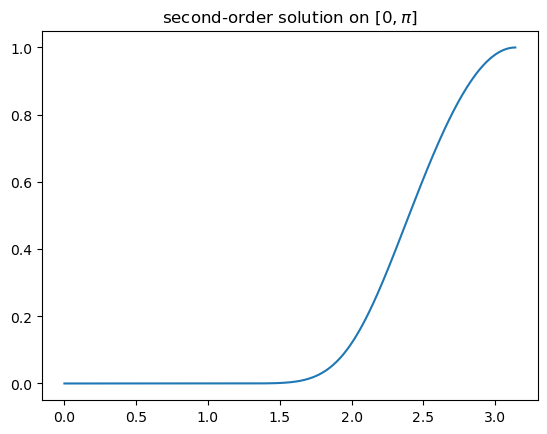

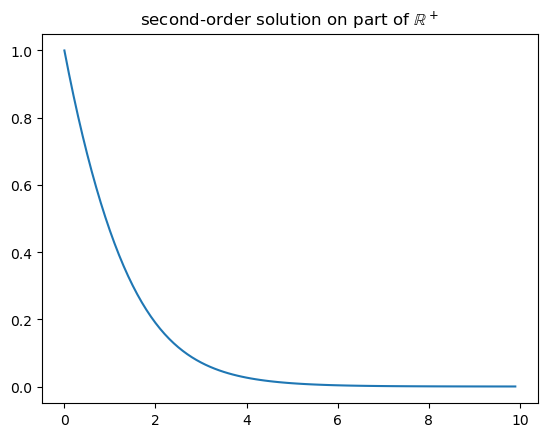

In [29]:
sigma = 1.0
mu = 1
gamma = 1
delta = 0.0
u0 = 1.0
u0xxx = None  # The common second-order formulation needs no third-derivative wall condition.
def some_func(x, a):
    return u0 * a.exp(-x)
problem = BSKProblem()
problem = BSKProblem(sigma=sigma, mu=mu, gamma=gamma, delta=delta, boundary_conditions=((u0, None, None, u0xxx, None), (None,)*5), initial_guess=some_func)
poisson = run_collocation(problem, N, L=L, tolerance=tolerance, method=use_method)
t = np.arange(0, np.pi, 0.01)
plt.title(r"second-order solution on $[0,\pi]$")
plt.plot(t, mapped_values(poisson, t))
plt.show()
x = np.arange(0.0, 10.0, 0.1)
plt.title(r"second-order solution on part of $\mathbb{R}^+$")
plt.plot(x, display_values(poisson.u, x))
plt.show()


## Bounded comparison of three globalization choices

The preceding fsolve comparison initializes NumPy collocation only; fsolve is
not an adjoint algorithm. Homotopy changes the equation parameter, whereas the
native adjoint fallback is a residual-merit descent recovery at fixed homotopy.
The following small catalog cases compare ordinary damped Newton, homotopy,
and enabling the adjoint fallback in both discretizations and arithmetics.
The reported adjoint step count may be zero when Newton already succeeds.
Reference continuation is also lazy: `reference_result` is `None` when the
initial physical Newton stage succeeds, even with globalization enabled.
The original research grids above remain unchanged.

Historical unsupported boundary sweeps have moved to
[`legacy_boundary_experiments.ipynb`](../../experiments/notebooks/legacy_boundary_experiments.ipynb).


In [30]:
from overscreening_breakdown.manufactured import rational_case

def compare_globalization_strategies(*, case=None, verbosity=2,
                                     progress_callback=None, progress_interval=1.0):
    if case is None:
        case = rational_case(nonlinear=True, beta="0.1", initial="exp")
    comparisons = {}
    for use_mpmath in (False, True):
        for solver, resolution in (("collocation", 8), ("galerkin", 4)):
            for label, options in (
                ("damped Newton", dict(use_globalization=False)),
                ("homotopy", dict(use_globalization=True)),
                ("adjoint fallback enabled", dict(use_globalization=False,
                                                   newton_fallback="adjoint")),
            ):
                key = (solver, "mpmath" if use_mpmath else "numpy", label)
                if verbosity:
                    print(key)
                current = solve(case.make_problem(), resolution, solver=solver,
                                use_mpmath=use_mpmath, precision=50,
                                tolerance="1e-35" if use_mpmath else "1e-10", initializer=None,
                                verbosity=verbosity, progress_callback=progress_callback,
                                progress_interval=progress_interval, **options)
                comparisons[key] = current
    return comparisons

comparison_case = rational_case(nonlinear=True, beta="0.1", initial="exp")
bounded_comparisons = compare_globalization_strategies(case=comparison_case)


('collocation', 'numpy', 'damped Newton')
[collocation/newton] solve_start N=8 precision=15 backend=numpy arithmetic=numpy tolerance=1.e-10 use_globalization=no initializer=- newton_fallback=- elapsed=0.000s
[collocation/newton] phase_start phase=problem_binding elapsed=0.001s
[collocation/newton] phase_end phase=problem_binding success=yes duration=0.000471017 elapsed=0.001s
[collocation/newton] problem_ready unknown_count=10 norm=rms elapsed=0.002s
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=8 unknown_count=10 elapsed=0.010s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=8 unknown_count=10 success=yes duration=0.03242281 elapsed=0.042s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.043s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.002883236 elapsed=0.046s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.046s
[collocation/newton] stage_residual norm

### Solution agreement and convergence

The figures below use the stored results; plotting does not rerun the solvers.
Each panel contains one discretization and arithmetic backend. We show the
solution profiles, differences from damped Newton together with its error
against the manufactured solution, and convergence relative to the actual
stage acceptance target (the horizontal line at one).

This bounded case normally needs neither reference continuation nor adjoint
recovery. Identical solutions and overlapping histories are expected: enabling
a recovery strategy does not mean it was used. The legends report actual use.
Exact zero differences are omitted from logarithmic curves and labelled
**identical**, without introducing an artificial error floor.

Field differences are calculated in the solution's native arithmetic before
conversion to Matplotlib display data. Convergence segments are kept separate
across changes of homotopy parameter or quadrature plan; the latter include
all plans, rather than only the final Newton result. The different arithmetic
tolerances are therefore shown through their own acceptance targets.

Three PDF figures are saved under `OUTPUT_DIR`, as well as displayed inline.


In [31]:
# Plot the stored comparisons without rerunning the solvers.
def plot_globalization_comparisons(comparisons, *, x_max="10", samples=201,
                                  exact_case=None):
    """Return solution, difference, and stage-convergence figures.

    Plotting performs no solves and changes no solution or numerical context.
    Zero/nonfinite log values are omitted, never replaced by an error floor.
    """
    if not comparisons:
        raise ValueError("at least one comparison result is required")
    if isinstance(samples, bool) or not isinstance(samples, int) or samples < 2:
        raise ValueError("samples must be an integer of at least two")
    if exact_case is None:
        exact_case = rational_case(nonlinear=True, beta="0.1", initial="exp")
    groups = sorted({key[:2] for key in comparisons},
                    key=lambda key: (key[0], key[1] != "numpy", key[1]))
    columns = min(2, len(groups))
    rows = (len(groups)+columns-1)//columns
    figures, panels = {}, {}
    for name, title in (
        ("solutions", "Solutions and manufactured reference"),
        ("differences", "Agreement between strategies and manufactured error"),
        ("convergence", "Convergence relative to each stage's acceptance target"),
    ):
        figure, axes = plt.subplots(rows, columns, figsize=(6.4*columns, 3.8*rows),
                                    squeeze=False)
        axes = list(axes.flat)
        for unused in axes[len(groups):]:
            figure.delaxes(unused)
        figures[name], panels[name] = figure, axes[:len(groups)]
        figure.suptitle(title)

    styles = {
        "damped Newton": ("-", "o"),
        "homotopy": ("--", "s"),
        "adjoint fallback enabled": (":", "x"),
    }

    def plan_results(solution):
        history = getattr(solution, "quadrature_history", ())
        results = [item.newton_result for item in history
                   if item.newton_result is not None]
        if not results and solution.newton_result is not None:
            results = [solution.newton_result]
        return results

    def positive_display(values, arithmetic):
        display = np.array([float(value) if arithmetic.isfinite(value) and value > 0
                            else np.nan for value in values], dtype=float)
        display[~np.isfinite(display) | (display <= 0)] = np.nan
        return display

    for panel, (solver, backend) in enumerate(groups):
        members = [(label, result) for (method, arithmetic, label), result in comparisons.items()
                   if (method, arithmetic) == (solver, backend)]
        members.sort(key=lambda item: (list(styles).index(item[0])
                                       if item[0] in styles else len(styles), item[0]))
        baseline_label, baseline = members[0]
        a = baseline.arithmetic
        right = a.scalar(x_max)
        if not a.isfinite(right) or right <= 0:
            raise ValueError("x_max must be finite and positive")
        points = [right*a.scalar(index)/(samples-1) for index in range(samples)]
        display_x = np.array([float(point) for point in points])
        values = {}
        for label, result in members:
            result.check_precision()
            values[label] = [a.scalar(result.u(point)) for point in points]
        exact = [a.scalar(exact_case.u(point, a)) for point in points]
        profile_ax = panels["solutions"][panel]
        difference_ax = panels["differences"][panel]
        convergence_ax = panels["convergence"][panel]
        arithmetic_label = "NumPy" if backend == "numpy" else "mpmath ({} dps)".format(a.dps)
        title = "{} / {}: N={}, {} unknowns".format(
            solver.capitalize(), arithmetic_label, baseline.N, baseline.unknown_count)
        for name in figures:
            panels[name][panel].set_title(title, fontsize=10)
        profile_ax.plot(display_x, [float(value) for value in exact], color="black",
                        linestyle="--", linewidth=2, alpha=0.5, label="manufactured exact")
        exact_error = [abs(value-reference) for value, reference in
                       zip(values[baseline_label], exact)]
        difference_ax.plot(display_x, positive_display(exact_error, a), color="black",
                           linestyle="--", label="|{} - exact|".format(baseline_label))
        identical = []
        all_log_values = list(exact_error)
        recovery_notes = []
        for index, (label, result) in enumerate(members):
            color = "C{}".format(index)
            linestyle, marker = styles.get(label, ("-", "o"))
            status = "" if result.converged else " [not converged]"
            profile_ax.plot(display_x, [float(value) for value in values[label]],
                            color=color, linestyle=linestyle, label=label+status)
            if label != baseline_label:
                # Subtract before display conversion: tiny mpmath differences
                # disappear if the two fields are rounded to float64 first.
                differences = [abs(value-base) for value, base in
                               zip(values[label], values[baseline_label])]
                same = all(value == 0 for value in differences)
                if same:
                    identical.append(label)
                difference_ax.plot(display_x, positive_display(differences, a), color=color,
                                   linestyle=linestyle,
                                   label="|{} - {}|{}".format(
                                       label, baseline_label, " (identical)" if same else ""))
                all_log_values.extend(differences)

            plans = plan_results(result)
            reference_used = any(getattr(plan, "reference_result", None) is not None
                                 for plan in plans)
            adjoint_steps = sum(plan.adjoint_steps for plan in plans)
            if label == "homotopy":
                recovery_notes.append("reference {}".format("used" if reference_used else "not needed"))
            if label == "adjoint fallback enabled":
                recovery_notes.append("{} adjoint recovery steps".format(adjoint_steps))
            curve_label = label+status
            if label == "homotopy" and not reference_used:
                curve_label += " (reference unused)"
            if label == "adjoint fallback enabled":
                curve_label += " ({} recovery steps)".format(adjoint_steps)
            labelled = False
            plan_offset = 0
            for plan in plans:
                stage_offset = 0
                for stage_index, stage in enumerate(plan.stages, 1):
                    target = a.scalar(stage.target_norm)
                    if not a.isfinite(target) or target <= 0:
                        raise ValueError("convergence plots require positive stage targets")
                    records = [record for record in plan.history if record.stage == stage_index]
                    attempts = [plan_offset+stage_offset]
                    norms = [a.scalar(stage.initial_norm)/target]
                    attempts.extend(plan_offset+record.iteration for record in records)
                    norms.extend(a.scalar(record.residual_norm)/target for record in records)
                    end = plan_offset+stage_offset+stage.iterations
                    if attempts[-1] != end:
                        attempts.append(end)
                        norms.append(a.scalar(stage.final_norm)/target)
                    # Each stage is a separate line: residuals from distinct
                    # equations or quadrature plans must not be connected.
                    convergence_ax.plot(
                        attempts, positive_display(norms, a), color=color,
                        linestyle=linestyle if stage.homotopy == 0 else "--", marker=marker,
                        markersize=4, markerfacecolor="none",
                        label=curve_label if not labelled else "_nolegend_")
                    labelled = True
                    first_ratio = positive_display([norms[0]], a)[0]
                    if stage.homotopy != 0 and np.isfinite(first_ratio):
                        convergence_ax.annotate("q={:.3g}".format(float(stage.homotopy)),
                                                (attempts[0], first_ratio),
                                                fontsize=7, color=color)
                    if not stage.converged:
                        convergence_ax.scatter([end], positive_display([norms[-1]], a),
                                               color=color, marker="v", s=30)
                    stage_offset += stage.iterations
                reference = getattr(plan, "reference_result", None)
                if reference is not None and reference.target_norm > 0:
                    initial_attempts = plan.stages[0].iterations if plan.stages else 0
                    ratio = a.scalar(reference.residual_norm)/a.scalar(reference.target_norm)
                    convergence_ax.scatter(
                        [plan_offset+initial_attempts], positive_display([ratio], a),
                        color=color, marker="D", s=25, label="{} reference (q=1)".format(label))
                plan_offset += plan.iterations

        if identical:
            difference_ax.text(0.03, 0.04, "Exact zero strategy differences omitted (identical).",
                               transform=difference_ax.transAxes, fontsize=8)
        if not any(a.isfinite(value) and value > 0 for value in all_log_values):
            difference_ax.set_ylim(0.1, 10)
            difference_ax.text(0.5, 0.5, "All sampled errors and differences are zero.",
                               transform=difference_ax.transAxes, ha="center", fontsize=9)
        difference_ax.set_yscale("log")
        convergence_ax.set_yscale("log")
        convergence_ax.axhline(1, color="0.4", linewidth=1, linestyle="--",
                               label="stage acceptance target")
        if recovery_notes:
            convergence_ax.text(0.03, 0.04, "; ".join(recovery_notes),
                                transform=convergence_ax.transAxes, fontsize=8)
        for axis in (profile_ax, difference_ax):
            axis.set_xlabel("physical coordinate x")
        profile_ax.set_ylabel("u(x)")
        difference_ax.set_ylabel("absolute difference / error")
        convergence_ax.set_xlabel("attempted Newton iteration (all quadrature plans)")
        norm_name = "RMS" if solver == "collocation" else "Euclidean"
        convergence_ax.set_ylabel("{} residual / stage target".format(norm_name))
        for axis in (profile_ax, difference_ax, convergence_ax):
            axis.grid(True, alpha=0.25)
            axis.legend(fontsize=8)
    for figure in figures.values():
        figure.tight_layout(rect=(0, 0, 1, 0.95))
    return figures


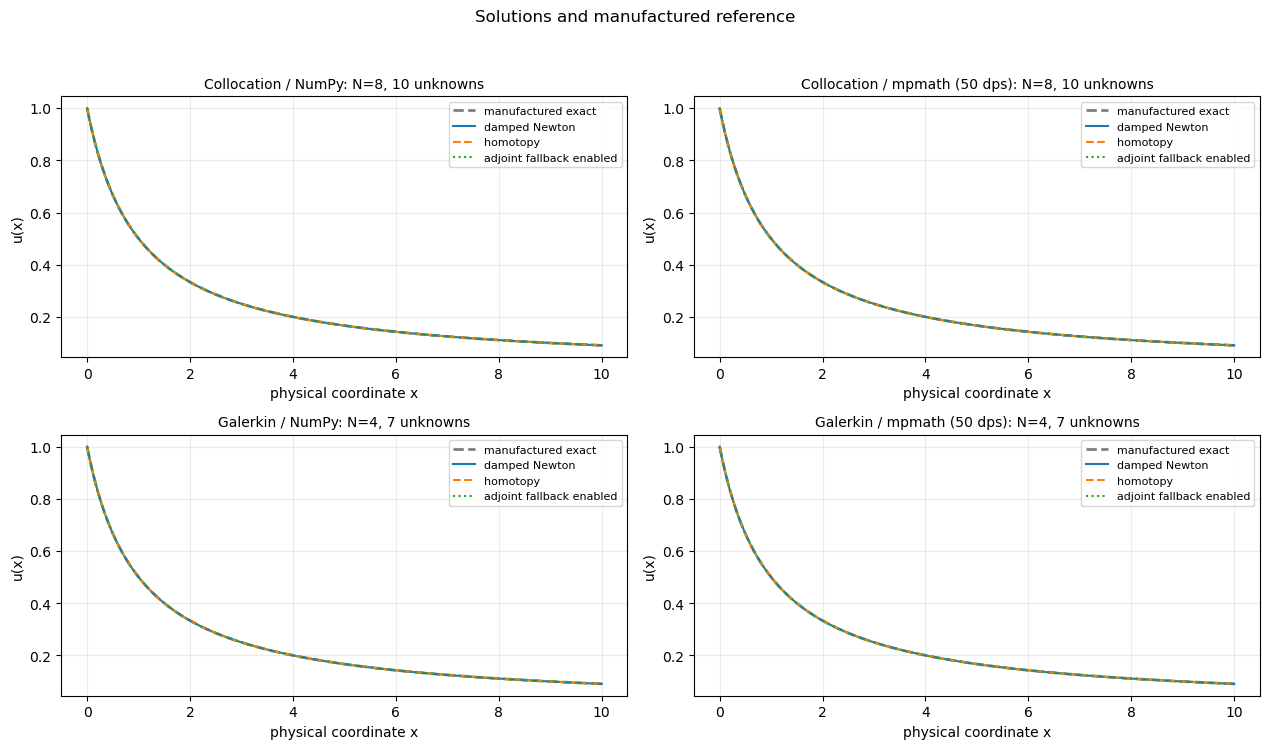

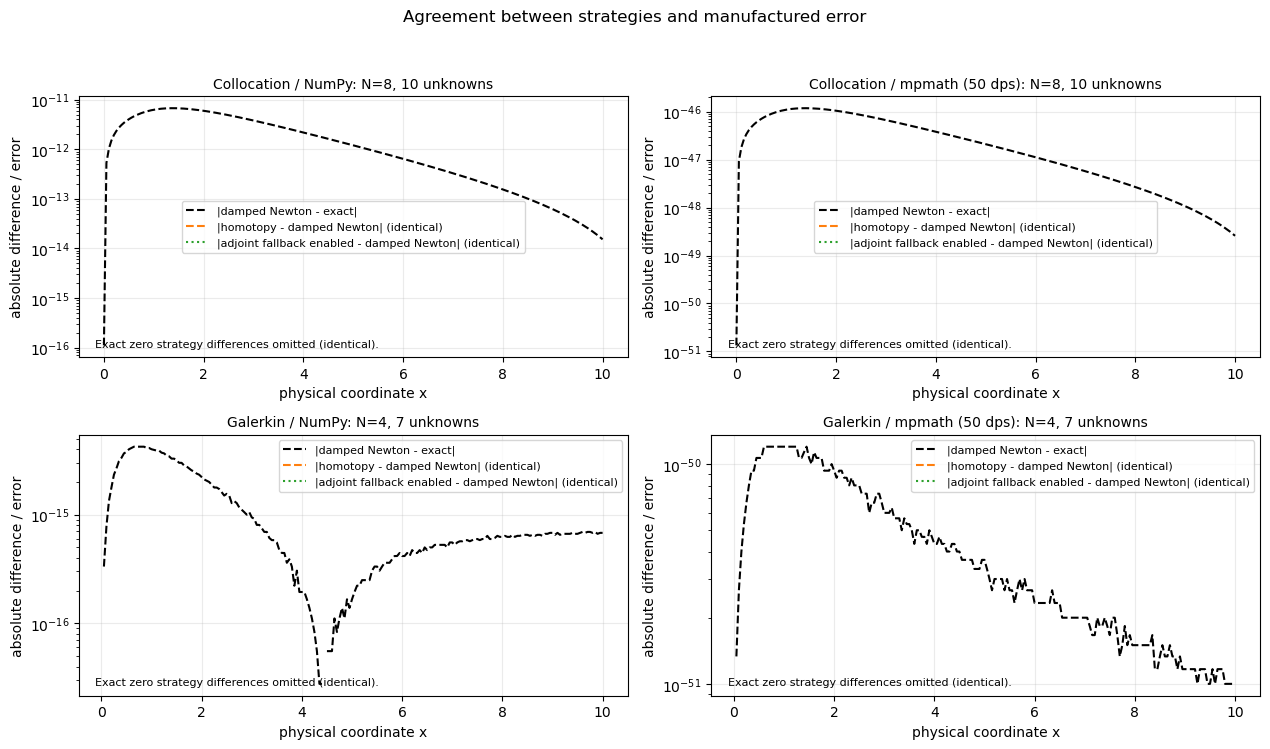

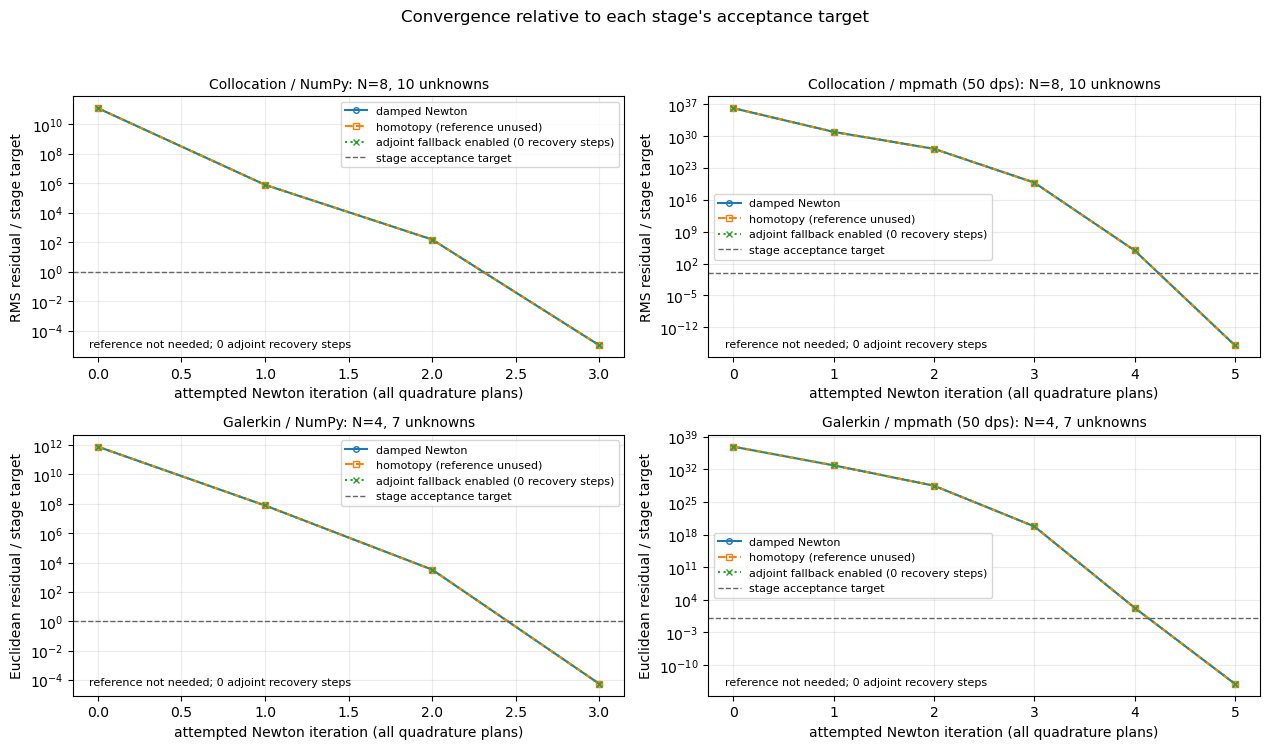

In [32]:
comparison_figures = plot_globalization_comparisons(
    bounded_comparisons, exact_case=comparison_case,
)
for name, figure in comparison_figures.items():
    figure.savefig(OUTPUT_DIR / ("globalization-" + name + ".pdf"))
plt.show()
